In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Day 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("/content/drive/MyDrive/food_dataset/train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/food_dataset/test.csv")
meal_info_df = pd.read_csv("/content/drive/MyDrive/food_dataset/meal_info.csv")
fulfilment_center_info_df = pd.read_csv("/content/drive/MyDrive/food_dataset/fulfilment_center_info.csv")

In [ ]:
datasets = {"Train": train_df,
                        "Test": test_df,
                        "Meal Info": meal_info_df,
                        "Fulfilment Center Info": fulfilment_center_info_df}

# Null Values
# for name, df in datasets.items():
#   print(f"\n{name}")
#   print(df.isnull().sum())

# Duplicate Values
  # for name, df in datasets.items():
  #   print(f"\n{name}")
  #   print(df.duplicated().sum())

In [ ]:
# train_df.info()
# test_df.info()
# meal_info_df.info()
# fulfilment_center_info_df.info()
# sample_submission_df.info()

In [ ]:
print("Train: ", train_df.columns.tolist())
print("Test: ", test_df.columns.tolist())
print("Meal Info: ", meal_info_df.columns.tolist())
print("FC: ", fulfilment_center_info_df.columns.tolist())

Train:  ['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']
Test:  ['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured']
Meal Info:  ['meal_id', 'category', 'cuisine']
FC:  ['center_id', 'city_code', 'region_code', 'center_type', 'op_area']


In [ ]:
# Merging Training Dataset
train_merge = train_df.merge(meal_info_df, on ="meal_id", how="left")
train_merge = train_merge.merge(fulfilment_center_info_df, on="center_id", how="left")

In [ ]:
# Merging Testing Dataset
test_merge = test_df.merge(meal_info_df, on="meal_id", how="left")
test_merge = test_merge.merge(fulfilment_center_info_df, on="center_id", how="left")

In [ ]:
print("Original Test: ", train_df.shape)
print("Merged Train : ", train_merge.shape)
print("Original Test: ", test_df.shape)
print("Merged Test: ", test_merge.shape)

Original Test:  (456548, 9)
Merged Train :  (456548, 15)
Original Test:  (32573, 8)
Merged Test:  (32573, 14)


In [ ]:
# print(train_merge.isnull().sum())
# print(test_merge.isnull().sum())

In [ ]:
# train_merge.info()
# test_merge.info()

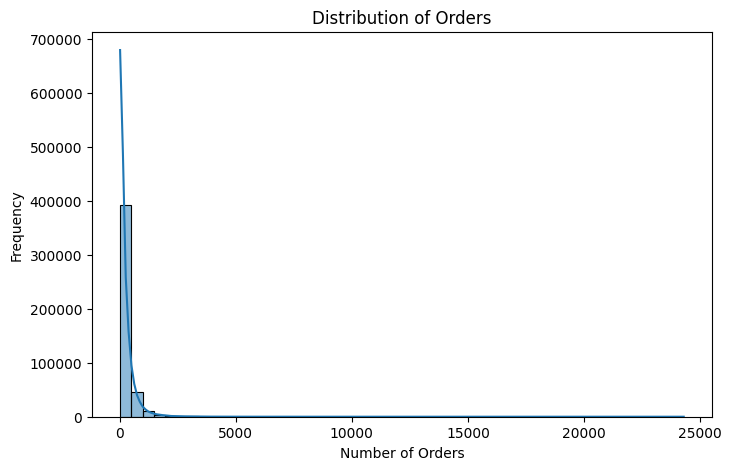

In [ ]:
# EDA

plt.figure(figsize=(8, 5))
sns.histplot(train_merge["num_orders"], bins=50, kde=True)
plt.title("Distribution of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Frequency")
plt.show()

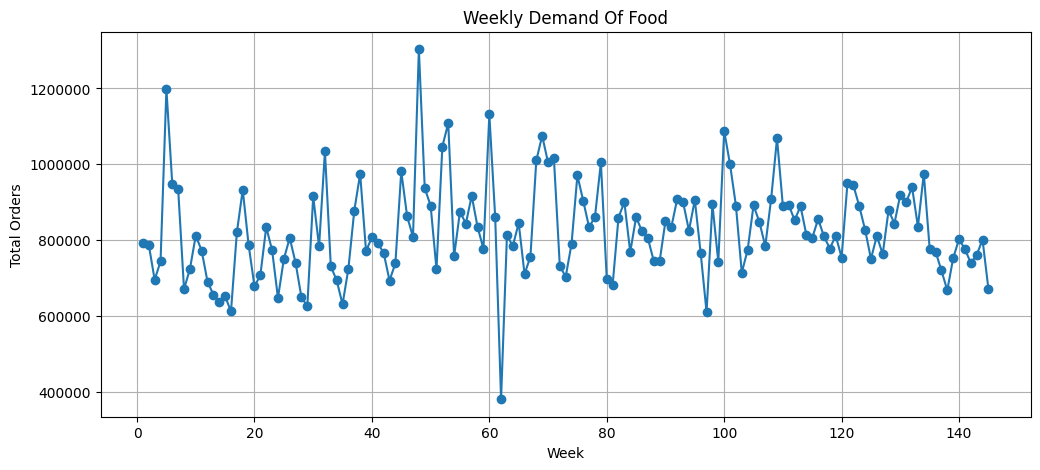

In [ ]:
weekly_demand = train_merge.groupby("week")["num_orders"].sum()
plt.figure(figsize=(12, 5))
weekly_demand.plot(marker='o')
plt.title("Weekly Demand Of Food")
plt.xlabel("Week")
plt.ylabel("Total Orders")
plt.ticklabel_format(axis="y", style="plain")
plt.grid()
plt.show()

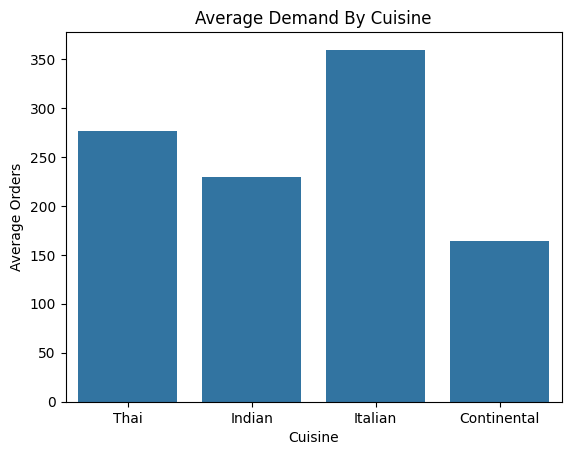

In [ ]:
sns.barplot(data=train_merge, x="cuisine", y="num_orders", estimator="mean", errorbar=None)
plt.title("Average Demand By Cuisine")
plt.xlabel("Cuisine")
plt.ylabel("Average Orders")
plt.show()

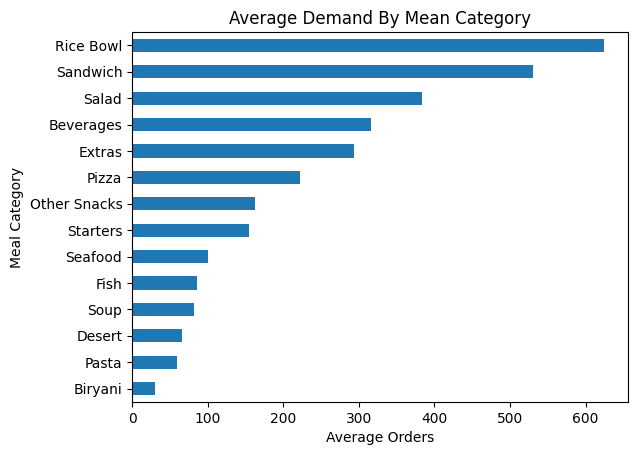

In [ ]:
category_demand = train_merge.groupby("category")["num_orders"].mean().sort_values()
category_demand.plot(kind="barh")
plt.title("Average Demand By Mean Category")
plt.xlabel("Average Orders")
plt.ylabel("Meal Category")
plt.show()

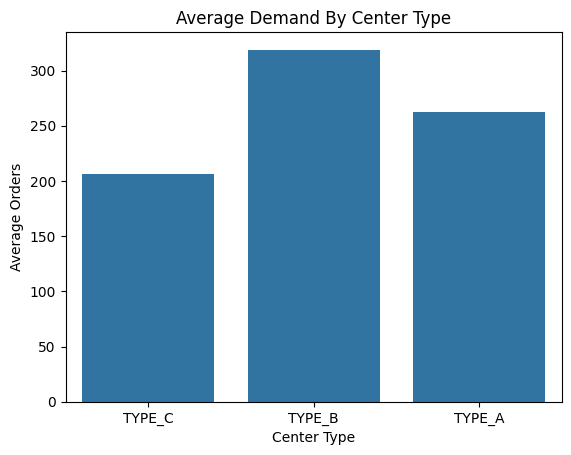

In [ ]:
sns.barplot(data=train_merge, x="center_type", y="num_orders", estimator="mean", errorbar=None)
plt.title("Average Demand By Center Type")
plt.xlabel("Center Type")
plt.ylabel("Average Orders")
plt.show()

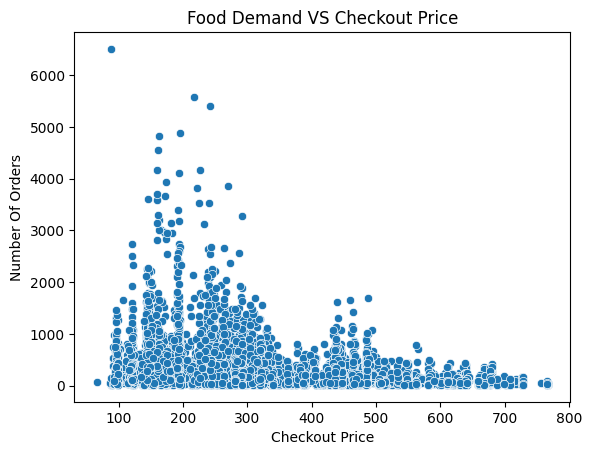

In [ ]:
sns.scatterplot(data=train_merge.sample(10000, random_state=42), x="checkout_price", y="num_orders")
plt.title("Food Demand VS Checkout Price")
plt.xlabel("Checkout Price")
plt.ylabel("Number Of Orders")
plt.show()

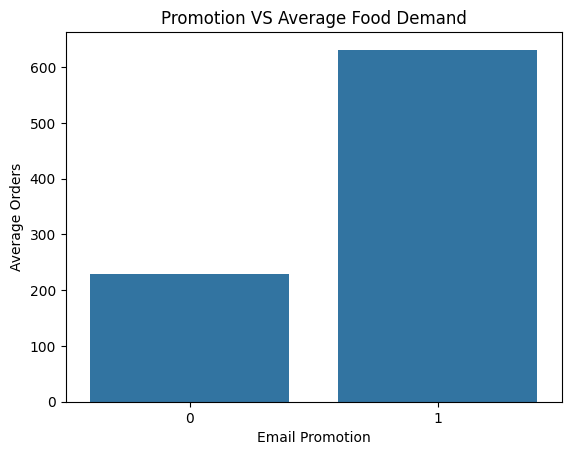

In [ ]:
sns.barplot(data=train_merge, x="emailer_for_promotion", y="num_orders", estimator="mean", errorbar=None)
plt.title("Promotion VS Average Food Demand")
plt.xlabel("Email Promotion")
plt.ylabel("Average Orders")
plt.show()

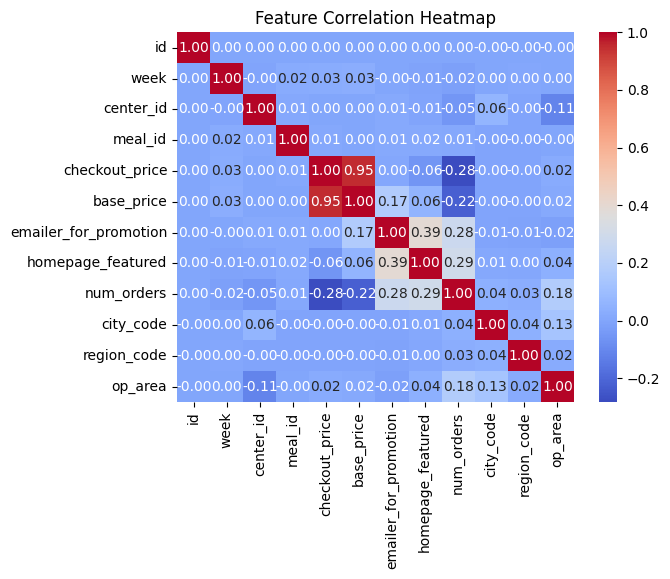

In [ ]:
numeric_df = train_merge.select_dtypes(include="number")
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
# Feature Engineering

# Adding Discount Amount Column

train_merge["discount_amount"] = train_merge["base_price"] - train_merge["checkout_price"]
test_merge["discount_amount"] = test_merge["base_price"] - test_merge["checkout_price"]

# Adding Discount Percentage
train_merge["discount_percentage"] = (train_merge["discount_amount"] / train_merge["base_price"].replace(0, np.nan)) * 100
test_merge["discount_percentage"] = (test_merge["discount_amount"] / test_merge["base_price"].replace(0, np.nan)) * 100

In [ ]:
# Creating a Combined Promotion Feature

train_merge["promotion_active"] = ((train_merge["emailer_for_promotion"] == 1) | (train_merge["homepage_featured"] == 1)).astype(int)
test_merge["promotion_active"] = ((test_merge["emailer_for_promotion"] == 1) | (test_merge["homepage_featured"] == 1)).astype(int)


In [ ]:
# Saving datasets

train_merge.to_csv("/content/drive/MyDrive/food_dataset/train_prepared.csv", index=False)
test_merge.to_csv("/content/drive/MyDrive/food_dataset/test_prepared.csv", index=False)

# Day 1 Ends